In [5]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/kartik2112/fraud-detection/fraudTrain.csv')

print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (1296675, 23)


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [7]:
# Missing values per column
print(df.isnull().sum())

# Duplicate rows
print("Duplicates:", df.duplicated().sum())

# Kitne fraud hain? (is_fraud: 1 = fraud, 0 = normal)
print(df['is_fraud'].value_counts())
print(df['is_fraud'].value_counts(normalize=True) * 100)

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64
Duplicates: 0
is_fraud
0    1289169
1       7506
Name: count, dtype: int64
is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


In [8]:
df = df.drop(columns=['Unnamed: 0'])

df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df['dob'] = pd.to_datetime(df['dob'])

df['hour'] = df['trans_date_trans_time'].dt.hour
df['day_of_week'] = df['trans_date_trans_time'].dt.day_name()
df['month'] = df['trans_date_trans_time'].dt.month
df['age'] = (df['trans_date_trans_time'] - df['dob']).dt.days // 365

df[['trans_date_trans_time', 'hour', 'day_of_week', 'age', 'amt', 'is_fraud']].head()

,trans_date_trans_time,hour,day_of_week,age,amt,is_fraud
0,2019-01-01 00:00:18,0,Tuesday,30,4.97,0
1,2019-01-01 00:00:44,0,Tuesday,40,107.23,0
2,2019-01-01 00:00:51,0,Tuesday,56,220.11,0
3,2019-01-01 00:01:16,0,Tuesday,52,45.00,0
4,2019-01-01 00:03:06,0,Tuesday,32,41.96,0


In [9]:
hourly = df.groupby('hour')['is_fraud'].agg(['count', 'sum', 'mean'])
hourly.columns = ['total_txns', 'fraud_txns', 'fraud_rate']
hourly['fraud_rate'] = (hourly['fraud_rate'] * 100).round(2)
hourly.sort_values('fraud_rate', ascending=False)

,total_txns,fraud_txns,fraud_rate
hour,,,
22,66982,1931,2.88
23,67104,1904,2.84
1,42869,658,1.53
0,42502,635,1.49
2,42656,625,1.47
3,42769,609,1.42
5,42171,60,0.14
7,42203,56,0.13
14,64885,86,0.13


In [10]:
cat = df.groupby('category')['is_fraud'].agg(['count', 'sum', 'mean'])
cat.columns = ['total_txns', 'fraud_txns', 'fraud_rate']
cat['fraud_rate'] = (cat['fraud_rate'] * 100).round(2)
cat.sort_values('fraud_rate', ascending=False)

,total_txns,fraud_txns,fraud_rate
category,,,
shopping_net,97543,1713,1.76
misc_net,63287,915,1.45
grocery_pos,123638,1743,1.41
shopping_pos,116672,843,0.72
gas_transport,131659,618,0.47
misc_pos,79655,250,0.31
travel,40507,116,0.29
grocery_net,45452,134,0.29
entertainment,94014,233,0.25


In [11]:
df['amt_bucket'] = pd.cut(df['amt'], bins=[0, 10, 50, 100, 250, 500, 1000, 30000])

amt = df.groupby('amt_bucket', observed=True)['is_fraud'].agg(['count', 'sum', 'mean'])
amt.columns = ['total_txns', 'fraud_txns', 'fraud_rate']
amt['fraud_rate'] = (amt['fraud_rate'] * 100).round(2)
amt

,total_txns,fraud_txns,fraud_rate
amt_bucket,,,
"(0, 10]",335929,525,0.16
"(10, 50]",336370,1082,0.32
"(50, 100]",389483,45,0.01
"(100, 250]",196435,244,0.12
"(250, 500]",22827,1962,8.60
"(500, 1000]",11695,2699,23.08
"(1000, 30000]",3936,949,24.11


In [12]:
df['age_group'] = pd.cut(df['age'], bins=[0, 25, 35, 45, 55, 65, 100])

age = df.groupby('age_group', observed=True)['is_fraud'].agg(['count', 'sum', 'mean'])
age.columns = ['total_txns', 'fraud_txns', 'fraud_rate']
age['fraud_rate'] = (age['fraud_rate'] * 100).round(2)
print(age)

gender = df.groupby('gender')['is_fraud'].agg(['count', 'sum', 'mean'])
gender.columns = ['total_txns', 'fraud_txns', 'fraud_rate']
gender['fraud_rate'] = (gender['fraud_rate'] * 100).round(2)
print(gender)

           total_txns  fraud_txns  fraud_rate
age_group                                    
(0, 25]        144604         895        0.62
(25, 35]       299697        1417        0.47
(35, 45]       266603        1146        0.43
(45, 55]       242995        1426        0.59
(55, 65]       163684        1244        0.76
(65, 100]      179092        1378        0.77
        total_txns  fraud_txns  fraud_rate
gender                                    
F           709863        3735        0.53
M           586812        3771        0.64


In [13]:
state = df.groupby('state')['is_fraud'].agg(['count', 'sum', 'mean'])
state.columns = ['total_txns', 'fraud_txns', 'fraud_rate']
state['fraud_rate'] = (state['fraud_rate'] * 100).round(2)
state.sort_values('fraud_rate', ascending=False).head(10)

,total_txns,fraud_txns,fraud_rate
state,,,
DE,9,9,100.00
RI,550,15,2.73
AK,2120,36,1.70
NV,5607,47,0.84
CO,13880,113,0.81
TN,17554,140,0.80
OR,18597,149,0.80
NE,24168,180,0.74
ME,16505,119,0.72


In [14]:
print("OVERALL FRAUD RATE:", round(df['is_fraud'].mean() * 100, 2))
print()
print("TOP 5 HOURS")
print(hourly.sort_values('fraud_rate', ascending=False).head(5))
print()
print("TOP 5 CATEGORIES")
print(cat.sort_values('fraud_rate', ascending=False).head(5))
print()
print("AMOUNT BUCKETS")
print(amt)
print()
print("AGE GROUPS")
print(age)
print()
print("GENDER")
print(gender)
print()
print("TOP 5 STATES")
print(state.sort_values('fraud_rate', ascending=False).head(5))

OVERALL FRAUD RATE: 0.58

TOP 5 HOURS
      total_txns  fraud_txns  fraud_rate
hour                                    
22         66982        1931        2.88
23         67104        1904        2.84
1          42869         658        1.53
0          42502         635        1.49
2          42656         625        1.47

TOP 5 CATEGORIES
               total_txns  fraud_txns  fraud_rate
category                                         
shopping_net        97543        1713        1.76
misc_net            63287         915        1.45
grocery_pos        123638        1743        1.41
shopping_pos       116672         843        0.72
gas_transport      131659         618        0.47

AMOUNT BUCKETS
               total_txns  fraud_txns  fraud_rate
amt_bucket                                       
(0, 10]            335929         525        0.16
(10, 50]           336370        1082        0.32
(50, 100]          389483          45        0.01
(100, 250]         196435         244    

In [15]:
df['flag'] = ((df['amt'] > 250) & ((df['hour'] >= 22) | (df['hour'] <= 3))).astype(int)

flagged = df[df['flag'] == 1]
print("Flagged transactions:", len(flagged))
print("Frauds caught:", flagged['is_fraud'].sum())
print("Precision %:", round(flagged['is_fraud'].mean() * 100, 2))
print("Recall %:", round(flagged['is_fraud'].sum() / df['is_fraud'].sum() * 100, 2))

Flagged transactions: 12073
Frauds caught: 4762
Precision %: 39.44
Recall %: 63.44


In [16]:
test = pd.read_csv('/kaggle/input/datasets/kartik2112/fraud-detection/fraudTest.csv')
test['trans_date_trans_time'] = pd.to_datetime(test['trans_date_trans_time'])
test['hour'] = test['trans_date_trans_time'].dt.hour

test['flag'] = ((test['amt'] > 250) & ((test['hour'] >= 22) | (test['hour'] <= 3))).astype(int)

flagged_t = test[test['flag'] == 1]
print("Test rows:", len(test))
print("Overall fraud rate %:", round(test['is_fraud'].mean() * 100, 2))
print("Flagged transactions:", len(flagged_t))
print("Frauds caught:", flagged_t['is_fraud'].sum())
print("Precision %:", round(flagged_t['is_fraud'].mean() * 100, 2))
print("Recall %:", round(flagged_t['is_fraud'].sum() / test['is_fraud'].sum() * 100, 2))

Test rows: 555719
Overall fraud rate %: 0.39
Flagged transactions: 4459
Frauds caught: 1343
Precision %: 30.12
Recall %: 62.61


In [17]:
test = pd.read_csv('/kaggle/input/datasets/kartik2112/fraud-detection/fraudTest.csv')
test = test.drop(columns=['Unnamed: 0'])
test['trans_date_trans_time'] = pd.to_datetime(test['trans_date_trans_time'])
test['dob'] = pd.to_datetime(test['dob'])
test['hour'] = test['trans_date_trans_time'].dt.hour
test['month'] = test['trans_date_trans_time'].dt.month
test['age'] = (test['trans_date_trans_time'] - test['dob']).dt.days // 365

features = ['amt', 'hour', 'month', 'age', 'city_pop', 'gender', 'category']

X_train = pd.get_dummies(df[features], columns=['gender', 'category'], drop_first=True)
X_test = pd.get_dummies(test[features], columns=['gender', 'category'], drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

y_train = df['is_fraud']
y_test = test['is_fraud']

print(X_train.shape, X_test.shape)
print(list(X_train.columns))

(1296675, 19) (555719, 19)
['amt', 'hour', 'month', 'age', 'city_pop', 'gender_M', 'category_food_dining', 'category_gas_transport', 'category_grocery_net', 'category_grocery_pos', 'category_health_fitness', 'category_home', 'category_kids_pets', 'category_misc_net', 'category_misc_pos', 'category_personal_care', 'category_shopping_net', 'category_shopping_pos', 'category_travel']


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return {
        'model': name,
        'precision': round(precision_score(y_test, pred) * 100, 2),
        'recall': round(recall_score(y_test, pred) * 100, 2),
        'f1': round(f1_score(y_test, pred) * 100, 2),
        'roc_auc': round(roc_auc_score(y_test, prob), 4),
        'pr_auc': round(average_precision_score(y_test, prob), 4)
    }

results = []

logreg = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))
results.append(evaluate('Logistic Regression', logreg))

tree = DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=42)
results.append(evaluate('Decision Tree', tree))

pd.DataFrame(results)

,model,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,3.49,73.80,6.66,0.9092,0.1213
1,Decision Tree,11.33,95.52,20.27,0.9834,0.2569


In [19]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=20,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)
results.append(evaluate('Random Forest', rf))

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=ratio,
    n_jobs=-1,
    random_state=42,
    eval_metric='aucpr'
)
results.append(evaluate('XGBoost', xgb))

pd.DataFrame(results)

,model,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,3.49,73.80,6.66,0.9092,0.1213
1,Decision Tree,11.33,95.52,20.27,0.9834,0.2569
2,Random Forest,22.77,94.41,36.69,0.9944,0.8386
3,XGBoost,27.53,95.62,42.76,0.9981,0.8872


In [21]:
prob = xgb.predict_proba(X_test)[:, 1]

rows = []
for t in [0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99]:
    pred = (prob >= t).astype(int)
    rows.append({
        'threshold': t,
        'flagged': pred.sum(),
        'precision': round(precision_score(y_test, pred) * 100, 2),
        'recall': round(recall_score(y_test, pred) * 100, 2)
    })

pd.DataFrame(rows)

,threshold,flagged,precision,recall
0,0.50,7449,27.53,95.62
1,0.70,5201,38.72,93.89
2,0.80,4290,45.99,91.98
3,0.90,3139,60.59,88.67
4,0.95,2339,76.27,83.17
5,0.98,1845,90.08,77.48
6,0.99,1692,93.38,73.66


In [22]:
imp = pd.Series(xgb.feature_importances_, index=X_train.columns)
imp.sort_values(ascending=False).head(10)

category_gas_transport    0.237525
amt                       0.178044
category_grocery_net      0.089938
category_food_dining      0.058671
category_home             0.053064
category_shopping_net     0.051000
hour                      0.050828
category_grocery_pos      0.046245
category_shopping_pos     0.046159
category_travel           0.040932
dtype: float32

In [23]:
big = df[df['amt'] > 250]
g = big.groupby('category')['is_fraud'].agg(['count', 'sum', 'mean'])
g.columns = ['total_txns', 'fraud_txns', 'fraud_rate']
g['fraud_rate'] = (g['fraud_rate'] * 100).round(2)
g.sort_values('fraud_rate', ascending=False)

,total_txns,fraud_txns,fraud_rate
category,,,
grocery_pos,1924,1739,90.38
shopping_net,8067,1713,21.23
misc_net,5201,915,17.59
home,872,103,11.81
entertainment,2036,233,11.44
shopping_pos,7886,843,10.69
misc_pos,4868,64,1.31
food_dining,542,0,0.00
health_fitness,535,0,0.00


In [24]:
gas = df[df['category'] == 'gas_transport']
print(gas.groupby('is_fraud')['amt'].describe().round(2))

             count   mean    std    min    25%    50%    75%     max
is_fraud                                                            
0         131041.0  63.68  15.53  17.00  52.65  62.93  73.41  154.03
1            618.0  12.29   4.53   5.93   9.09  10.64  14.06   24.84


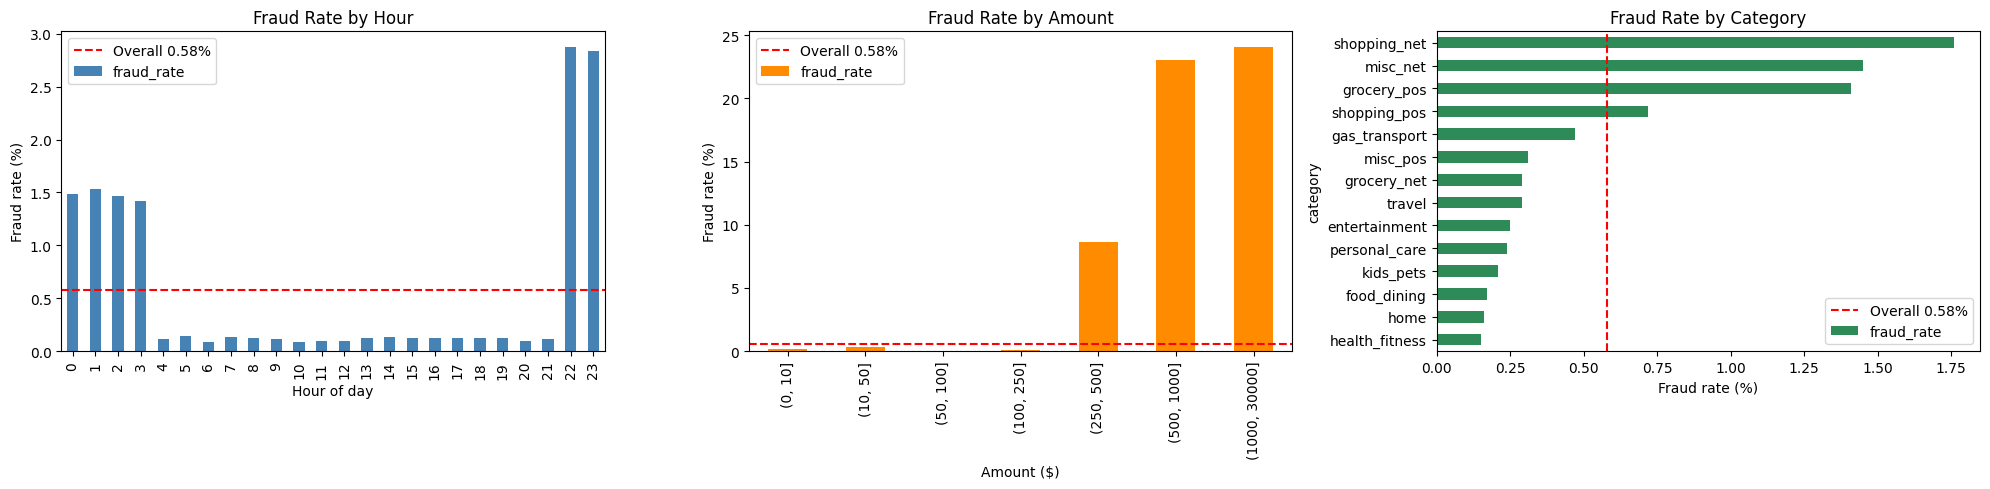

In [25]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

hourly['fraud_rate'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].axhline(0.58, color='red', linestyle='--', label='Overall 0.58%')
axes[0].set_title('Fraud Rate by Hour')
axes[0].set_xlabel('Hour of day')
axes[0].set_ylabel('Fraud rate (%)')
axes[0].legend()

amt['fraud_rate'].plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].axhline(0.58, color='red', linestyle='--', label='Overall 0.58%')
axes[1].set_title('Fraud Rate by Amount')
axes[1].set_xlabel('Amount ($)')
axes[1].set_ylabel('Fraud rate (%)')
axes[1].legend()

cat['fraud_rate'].sort_values().plot(kind='barh', ax=axes[2], color='seagreen')
axes[2].axvline(0.58, color='red', linestyle='--', label='Overall 0.58%')
axes[2].set_title('Fraud Rate by Category')
axes[2].set_xlabel('Fraud rate (%)')
axes[2].legend()

plt.tight_layout()
plt.show()